# Restart is bitwise

`restart_sp`: `decks/shell_sp.athinput` run 16 cycles straight, and 8 cycles + a restart dump +
8 more cycles from the restart. `restart_cs`: the cubed sphere, 8 straight vs 4 + 4.
Criterion: the final dumps and the history rows after the restart are identical
(largest difference exactly 0).

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath('.'))   # this notebook's folder: tests/vet_clean/notebooks
import nbutil as nb                        # nb.suite, nb.verdict, nb.vett (readers), nb.rt (run_tests)

# the athena binary (a CPU build, default the one tests/vet_clean/run_tests.sh builds)
EXE = os.path.abspath(os.environ.get('ATHENA_EXE', '../../../build_vettest/src/athena'))
# where the runs go; a test whose run is already there is only loaded, not rerun
WORK = os.path.abspath(os.environ.get('M1_NB_WORKDIR', 'runs'))
THREADS = int(os.environ.get('M1_NB_THREADS', '4'))   # OpenMP threads per run
plt.rcParams.update({'figure.dpi': 80, 'savefig.dpi': 80, 'font.size': 10})
print('binary', os.path.relpath(EXE), '\nruns  ', os.path.relpath(WORK))

binary ../../../build_vettest/src/athena 
runs   runs


In [2]:
TESTS = {'restart_sp': 'sp', 'restart_cs': 'cs'}
res = {t: nb.suite(t, EXE, WORK, THREADS) for t in TESTS}

loading the existing run runs/restart_sp
loading the existing run runs/restart_cs


restart_sp : history Er, restarted - straight = [0. 0. 0. 0. 0. 0. 0. 0.]
   final vet      dump (cycle 16): max |difference| = 0.0
   final hydro_u  dump (cycle 16): max |difference| = 0.0
restart_cs : history Er, restarted - straight = [0. 0. 0. 0.]
   final vet      dump (cycle 8): max |difference| = 0.0
   final hydro_u  dump (cycle 8): max |difference| = 0.0


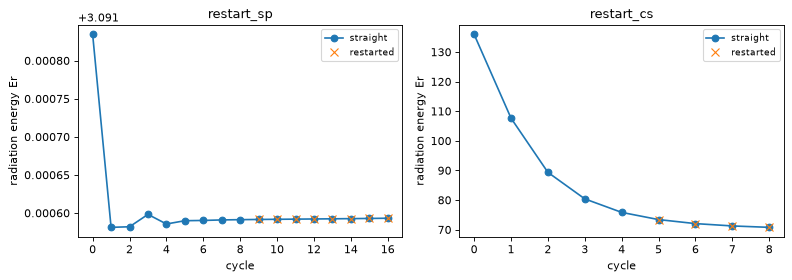

In [3]:
vett = nb.vett
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, (t, base) in zip(axs, TESTS.items()):
    a, b = os.path.join(WORK, t, 'straight'), os.path.join(WORK, t, 'restarted')
    ha = nb.rt.hst_col(os.path.join(a, base + '.user.hst'), 'Er')
    hb = nb.rt.hst_col(os.path.join(b, base + '.user.hst'), 'Er')   # rows after the restart
    ca, cb = np.arange(len(ha)), np.arange(len(ha) - len(hb), len(ha))
    ax.plot(ca, ha, 'o-', label='straight')
    ax.plot(cb, hb, 'x', ms=8, label='restarted')
    ax.set(xlabel='cycle', ylabel='radiation energy Er', title=t); ax.legend(fontsize=8)
    print(t, ': history Er, restarted - straight =', hb - ha[len(ha) - len(hb):])
    for v in ('vet', 'hydro_u'):
        x, y = vett.last_bin(a, v), vett.last_bin(b, v)
        print('   final %-8s dump (cycle %d): max |difference| = %s' % (
            v, x['cycle'], max(np.abs(x[k] - y[k]).max() for k in x['_names'])))
plt.tight_layout(); plt.show()

In [4]:
for t in TESTS:
    print(t, res[t]); nb.verdict(t, res[t])

restart_sp {'files': 4, 'maxdiff': 0.0, 'wall': 16.26279592514038}
PASS restart_sp   criterion {"equal": {"maxdiff": 0.0}}
restart_cs {'files': 4, 'maxdiff': 0.0, 'wall': 14.706427574157715}
PASS restart_cs   criterion {"equal": {"maxdiff": 0.0}}
